In [61]:
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, accuracy_score

In [42]:
if file := input("Enter Dataset: "):
  df = pd.read_csv(file)

Enter Dataset: dataset.csv


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   square_feet           10000 non-null  float64
 1   num_rooms             10000 non-null  int64  
 2   age                   10000 non-null  int64  
 3   distance_to_city(km)  10000 non-null  float64
 4   price                 10000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 390.8 KB


In [44]:
df = pd.get_dummies(df)

In [45]:
df.head(10)

,square_feet,num_rooms,age,distance_to_city(km),price
0,2248.357077,3,92,22.997972,200374.090410
1,1930.867849,2,22,13.984254,268784.847337
2,2323.844269,6,33,21.500945,315020.857676
3,2761.514928,3,63,10.343638,355111.468459
4,1882.923313,7,54,25.485200,234197.123903
5,1882.931522,2,70,16.510014,171397.001685
6,2789.606408,6,8,28.364627,438704.163041
7,2383.717365,5,3,3.285625,438745.704315
8,1765.262807,7,65,15.914028,243125.068444
9,2271.280022,3,90,23.227202,171466.048061


In [46]:
df.tail(10)

,square_feet,num_rooms,age,distance_to_city(km),price
9990,2716.812510,2,23,8.872441,404929.550657
9991,2095.725358,6,26,10.733120,336961.412391
9992,2331.084377,2,35,7.765745,298269.423011
9993,1250.682251,3,16,1.087231,196267.064371
9994,2597.107242,5,55,21.083957,347573.877731
9995,2650.551032,7,9,18.126034,431344.267823
9996,1000.827516,2,53,24.479692,6650.271134
9997,1647.341638,5,80,2.189312,233698.384301
9998,2247.882787,6,73,27.931014,280766.827379
9999,2322.194227,7,73,10.595721,342895.309114


<Axes: xlabel='num_rooms', ylabel='price'>

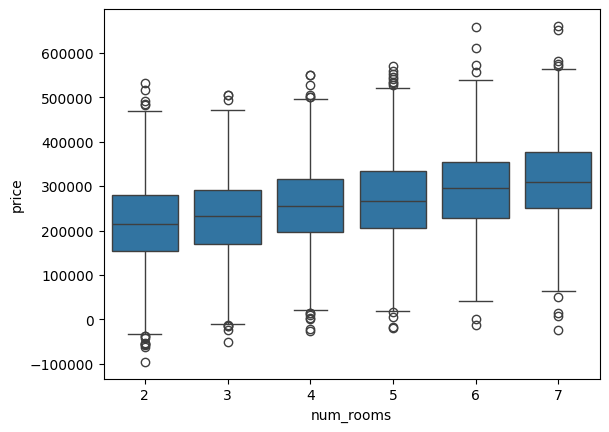

In [47]:
sns.boxplot(
    data=df, x="num_rooms", y="price"
)

In [48]:
len(df[df['price'] > 600000])

4

In [49]:
df = df[df['price'] <= 600000]

In [50]:
len(df[df['price'] < 10000])

55

In [51]:
df = df[df['price'] >= 10000]

In [52]:
df.head(10)

,square_feet,num_rooms,age,distance_to_city(km),price
0,2248.357077,3,92,22.997972,200374.090410
1,1930.867849,2,22,13.984254,268784.847337
2,2323.844269,6,33,21.500945,315020.857676
3,2761.514928,3,63,10.343638,355111.468459
4,1882.923313,7,54,25.485200,234197.123903
5,1882.931522,2,70,16.510014,171397.001685
6,2789.606408,6,8,28.364627,438704.163041
7,2383.717365,5,3,3.285625,438745.704315
8,1765.262807,7,65,15.914028,243125.068444
9,2271.280022,3,90,23.227202,171466.048061


<Axes: xlabel='num_rooms', ylabel='price'>

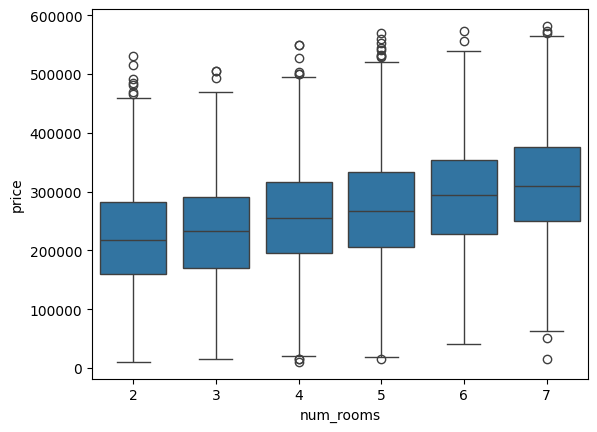

In [53]:
sns.boxplot(
    data=df, x="num_rooms", y="price"
)

In [54]:
X = df.drop(
    columns=[
        "price"
    ]
)
y = df['price']

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42, shuffle=True, train_size=0.85
)

In [65]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [67]:
score = model.score(X_test, y_test)
score

0.9554052295510351

In [70]:
import joblib
joblib.dump(model, "model.pkl")

['model.pkl']

In [71]:
from google.colab import files
files.download("model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>